# Both Pumps Trip: Coastdown, Trip, Flapper, Natural Convection

This page takes the pool reactor of the previous example through the loss of both pumps and follows it for an hour. The sequence it should produce is:

1. Both pumps lose their head at 10 s, over half a second.
2. The flow decays slowly, carried by the two flywheels.
3. The low-flow trip fires when the flow falls to 85 % of nominal, and the rods drop half a second later.
4. The flapper, which joins the plenum below the core to the bottom of the pool beside it, opens when the flow falls to 30 % of nominal, and the pool becomes a path for the flow.
5. The heated groups reverse one after the other, the hottest first, and the core flow turns upward.
6. The flow in the pump legs dies out, and their check valves hold back all but a small leak.
7. The loop settles into natural circulation: up through the core, down through the pool, back through the flapper.

Each step below is checked against what the solution shows, and the hour is closed with an energy balance and a pressure balance around the natural-circulation loop.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import rc

rc("font", family="serif", size=15)

from stream.examples.lofa import CORE, HEATED, Params, both_pumps, energy_budget, loop_pressure_budget, operating_point
from stream.examples.lofa.params import BETA
from stream.examples.lofa.scenarios import flows
from stream.substances import light_water

## Running the hour

`both_pumps` solves the operating point of the previous page, switches both pumps from imposed flow to imposed head at their solved heads, ramps the heads to zero and integrates for an hour at 1801 output times, one every 2 s. It returns the solution and a `Record` of what happened: the status, the times of the events, the peak coolant temperature and its margin to saturation, and the state of the loop at the end.

In [2]:
p = Params()
sol, rec = both_pumps(p)
print(f"status:                     {rec.status}")
print(f"reactor trip:               {rec.t_trip:.2f} s")
print(f"rods start moving:          {rec.t_rods:.2f} s")
print(f"flapper opens:              {rec.t_open:.2f} s")
print(f"check valves shut, A and B: {rec.t_valve_A:.0f} s, {rec.t_valve_B:.0f} s")
print(f"hot group reverses:         {rec.t_rev_hot:.0f} s")
print(f"normal group reverses:      {rec.t_rev_normal:.0f} s")
print(f"low group reverses:         {rec.t_rev_low:.0f} s")
print(f"peak coolant temperature:   {rec.peak_max:.2f} °C")
print(f"margin to saturation:       {rec.margin:.2f} K")
print(f"flapper flow at the hour:   {rec.final_flapper:.2f} kg/s")
print(f"pool temperature rise:      {rec.pool_rise:.2f} K")

status:                     completed
reactor trip:               12.49 s
rods start moving:          12.99 s
flapper opens:              38.89 s
check valves shut, A and B: 490 s, 490 s
hot group reverses:         200 s
normal group reverses:      246 s
low group reverses:         280 s
peak coolant temperature:   100.87 °C
margin to saturation:       15.97 K
flapper flow at the hour:   1.51 kg/s
pool temperature rise:      0.41 K


The run reaches the hour. The flow falls to the trip setpoint at about 12.5 s, about two and a half seconds after the pumps lose their head, and the rods start moving half a second later. The flapper opens at about 39 s. The three heated groups reverse between about 200 and 280 s, hot plate first, low plates last, and both pump legs count as shut at about 490 s.

The trip and the flapper opening are events the solver locates in time. The reversal and valve times are not: they are the first output time at which the flow has crossed its threshold (a reversal is a per-plate flow below -0.001 kg/s, a shut valve a leg flow below 1 % of its nominal value), so they are known to the 2 s spacing of the output grid.

The flows over the first two minutes show the first four steps. `flows` reads the flow of every edge of interest out of the solution; it needs the loop's aggregator and Kirchhoff calculation, which `operating_point` rebuilds identically. The vertical lines mark the pumps tripping, the reactor trip and the flapper opening, and do so on every figure of this page.

trip threshold:                     205.30 kg/s
riser flow crosses it, interpolated: 12.54 s
reactor trip, located by the solver: 12.49 s


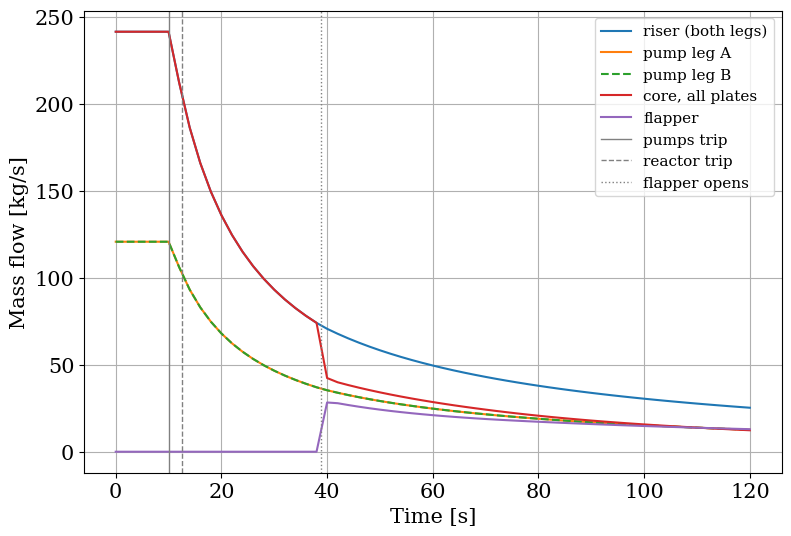

In [3]:
agr, K, refs, y = operating_point(p)
df = flows(agr, K, refs, sol)
df["core"] = sum(CORE[k].plates * df[k] for k in CORE)
events = {"pumps trip": p.t_pumps, "reactor trip": rec.t_trip, "flapper opens": rec.t_open}


def mark(ax):
    for (label, t), style in zip(events.items(), ["-", "--", ":"]):
        ax.axvline(t, color="gray", linewidth=1, linestyle=style, label=label)


i = np.flatnonzero(df.riser.to_numpy() < refs["trip"].threshold)[0]
crossing = np.interp(refs["trip"].threshold, df.riser.iloc[[i, i - 1]], df.t.iloc[[i, i - 1]])
print(f"trip threshold:                     {refs['trip'].threshold:.2f} kg/s")
print(f"riser flow crosses it, interpolated: {crossing:.2f} s")
print(f"reactor trip, located by the solver: {rec.t_trip:.2f} s")
first = df[df.t <= 120]
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(first.t, first.riser, label="riser (both legs)")
ax.plot(first.t, first.A, label="pump leg A")
ax.plot(first.t, first.B, "--", label="pump leg B")
ax.plot(first.t, first.core, label="core, all plates")
ax.plot(first.t, first.flapper, label="flapper")
mark(ax)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Mass flow [kg/s]")
ax.legend(fontsize=11)
ax.grid()
plt.show()

The trip watches the riser flow. On the output grid that flow is first below the threshold at the 14 s sample; interpolating linearly between that sample and the one before puts the crossing at about 12.54 s, about 0.05 s after the trip time the solver located, about 12.49 s. The interpolated time is the later one, as it must be: the coastdown curves upward between samples, so the straight line between them lies above it and reaches the threshold late.

Until the flapper opens, the riser and the core carry the same water, so their curves coincide, and the two legs share it equally, so theirs coincide too. When the flapper opens, the pumps' suction finds a second path, from the bottom of the pool beside the core straight into the plenum below it, and the core flow drops sharply while the riser flow continues smoothly: the flywheels see little change in the loop's resistance, the core sees a new parallel path.

## The flywheel tail

The coastdown example, [Primary Cooling System Coastdown](PCSCoastdown.ipynb), derives what a flywheel does to a loop whose pump stops: with inertia $L$ and a quadratic loss $k\dot m^2$, the flow decays as

$$\dot m(t) = \frac{\dot m_0}{1 + \dot m_0 \alpha t}, \qquad \alpha = k / L.$$

Here each leg has its own flywheel, so the formula applies leg by leg with $\dot m_0$ the nominal leg flow. Before the trip the pump head $\Delta p$ balances the loop's loss at that flow, $k \dot m_0^2 = \Delta p$, which gives $\dot m_0 \alpha = \Delta p / (L \dot m_0)$: the flow halves after

$$t_{1/2} = \frac{L \dot m_0}{\Delta p},$$

counted from the pump trip. The record keeps that estimate, from the solved pump head and the flywheel's inertia, as `t_half_hand`, and the first output time at which the riser flow is below half its initial value as `t_half`, counted from the start of the run. The estimate holds only while the loop is the one the pumps drove, so the comparison stops at the flapper opening.

half-flow time, flywheel estimate: 12.76 s
half-flow time, sampled:           14.00 s


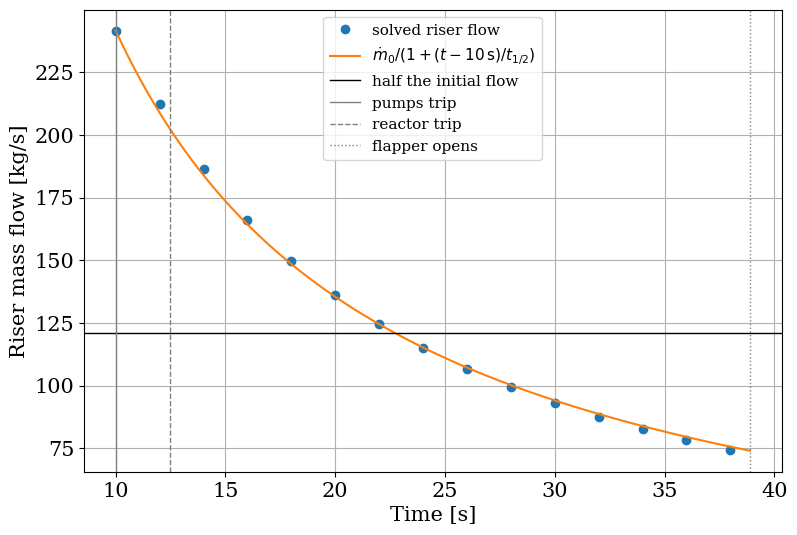

In [4]:
t_half_hand = rec.t_half_hand
print(f"half-flow time, flywheel estimate: {t_half_hand:.2f} s")
print(f"half-flow time, sampled:           {rec.t_half - p.t_pumps:.2f} s")
tail = df[(df.t >= p.t_pumps) & (df.t <= rec.t_open)]
t = np.linspace(p.t_pumps, rec.t_open, 200)
hyperbola = df.riser.iloc[0] / (1 + (t - p.t_pumps) / t_half_hand)
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(tail.t, tail.riser, "o", label="solved riser flow")
ax.plot(t, hyperbola, label=r"$\dot m_0 / (1 + (t - 10\,\mathrm{s}) / t_{1/2})$")
ax.axhline(df.riser.iloc[0] / 2, color="black", linewidth=1, label="half the initial flow")
mark(ax)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Riser mass flow [kg/s]")
ax.legend(fontsize=11)
ax.grid()
plt.show()

The estimate gives about 12.8 s and the sampled time is about 14 s. The sampled time is the first output time past the half-flow point, so it can be up to 2 s late; the curve shows the agreement better than the two numbers: the solved flow follows the hyperbola from the trip to the flapper opening, with the small departures expected from what the estimate leaves out, the half-second ramp of the pump heads and the inertia of the water in the core, the pool and the decay tank.

## The core reverses

Once the forced flow is weak, the heated plates feel their own buoyancy. Each group is a column of water warmer than the pool around it, so it pushes upward against the dying downward flow, and the hottest group per unit flow pushes hardest. The figure shows the flow of one plate of each group on a symmetric logarithmic axis, linear within 0.001 kg/s of zero, with each group's reversal time marked by a dashed line in its colour. The time axis is linear over the first 10 s and logarithmic after.

net core flow first upward at:    262 s
pump legs first backward at:      626 s
leg flow at the hour:             -0.045 kg/s
bypass changes sign 7 times, from 262 to 294 s
bypass changes by more than 0.001 kg/s between samples until 312 s
from 262 to 312 s: bypass -0.035 to 0.024 kg/s, hot plate -0.005 to -0.004 kg/s


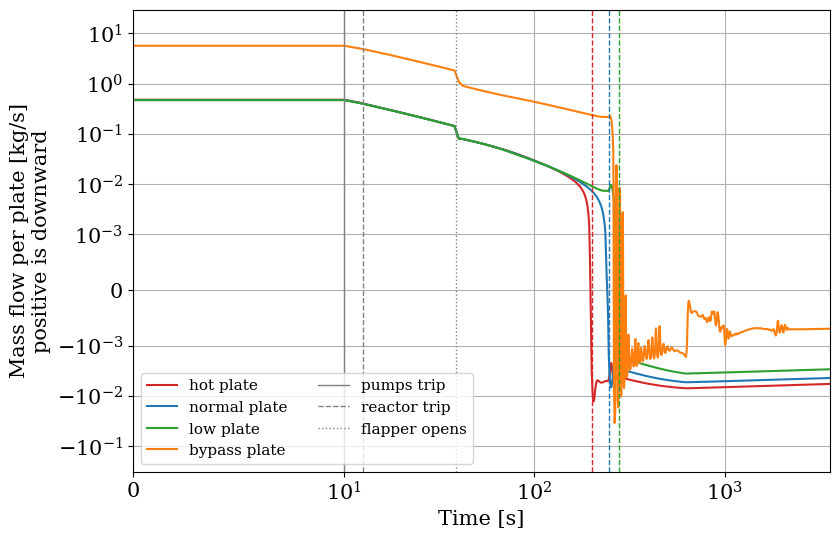

In [5]:
colours = dict(zip(CORE, ["C3", "C0", "C2", "C1"]))
reversals = {"hot": rec.t_rev_hot, "normal": rec.t_rev_normal, "low": rec.t_rev_low}
t_core = df.t.iloc[np.flatnonzero(df.core.to_numpy() < 0)[0]]
print(f"net core flow first upward at:    {t_core:.0f} s")
print(f"pump legs first backward at:      {df.t.iloc[np.flatnonzero(df.riser.to_numpy() < 0)[0]]:.0f} s")
print(f"leg flow at the hour:             {rec.final_leg_A:.3f} kg/s")
flips = df.t.to_numpy()[1:][np.diff(np.sign(df.bypass.to_numpy())) != 0]
steps = df.t.to_numpy()[1:][np.abs(np.diff(df.bypass.to_numpy())) > 1e-3]
swing = df[(df.t >= flips[0]) & (df.t <= steps[-1])]
print(f"bypass changes sign {len(flips)} times, from {flips[0]:.0f} to {flips[-1]:.0f} s")
print(f"bypass changes by more than 0.001 kg/s between samples until {steps[-1]:.0f} s")
print(f"from {flips[0]:.0f} to {steps[-1]:.0f} s: bypass {swing.bypass.min():.3f} to {swing.bypass.max():.3f} kg/s, hot plate {swing.hot.min():.3f} to {swing.hot.max():.3f} kg/s")
fig, ax = plt.subplots(figsize=(9, 6))
for k in CORE:
    ax.plot(df.t, df[k], color=colours[k], label=f"{k} plate")
for k in HEATED:
    ax.axvline(reversals[k], color=colours[k], linewidth=1, linestyle="--")
mark(ax)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, sol.time[-1])
ax.set_xlabel("Time [s]")
ax.set_ylim(top=30)
ax.set_ylabel("Mass flow per plate [kg/s]\npositive is downward")
ax.legend(fontsize=11, ncol=2)
ax.grid()
plt.show()

The flows fall together until the flapper opens, then all four drop at once as the flapper takes part of the pumps' suction. As the forced flow keeps weakening, the hot plate stands still and turns upward first, at about 200 s, while the rest of the core is still flowing down: for about a minute the core recirculates internally, water going down the normal, low and bypass channels and up the hot one. The normal plates follow at about 246 s, the net flow through the core turns upward at about 262 s, and the low plates reverse last, at about 280 s. The heated groups reverse in the order of their power per unit flow, which is the buoyancy each has to push with. The bypass, unheated, has no buoyancy of its own, and it does not settle the way the heated plates do. On the output grid it changes sign 7 times between about 262 and 294 s, swinging between about -0.035 and 0.024 kg/s per channel, several times the hot plate's flow at the time, and its changes from one sample to the next exceed 0.001 kg/s until about 312 s. After that it carries a small upward flow, with wiggles below that size that the symmetric axis, linear near zero, makes look larger than they are. This page does not resolve what drives the oscillation.

The flywheels keep the pump legs flowing forward long after the core has reversed, and as long as they do, the flapper feeds both the core and the legs. The legs' flow turns backward at about 626 s; the check valves let through only a backward leak, about 0.045 kg/s per leg at the end of the hour, and the kink in every curve at that time, including the jump of the bypass toward zero, is the loop losing its last forced flow. From then on the per-plate flows are the natural circulation, declining slowly with the decay heat for the rest of the hour.

## Power and reactivity

The point-kinetics node reads the trip through its reactivity controller, which inserts the rods' reactivity once the trip's delay has passed. `both_pumps` returns the solution, not the loop it ran on, and the loop rebuilt above has a trip sensor that never fired; it is given the run's trip time so that its controller reports the reactivity the run saw. Saving the state at an output time then gives the total reactivity, rods and temperature feedback together, which is plotted in dollars.

reactivity at 60 s: -9.86 dollars
power at 60 s:      3.7 % of nominal


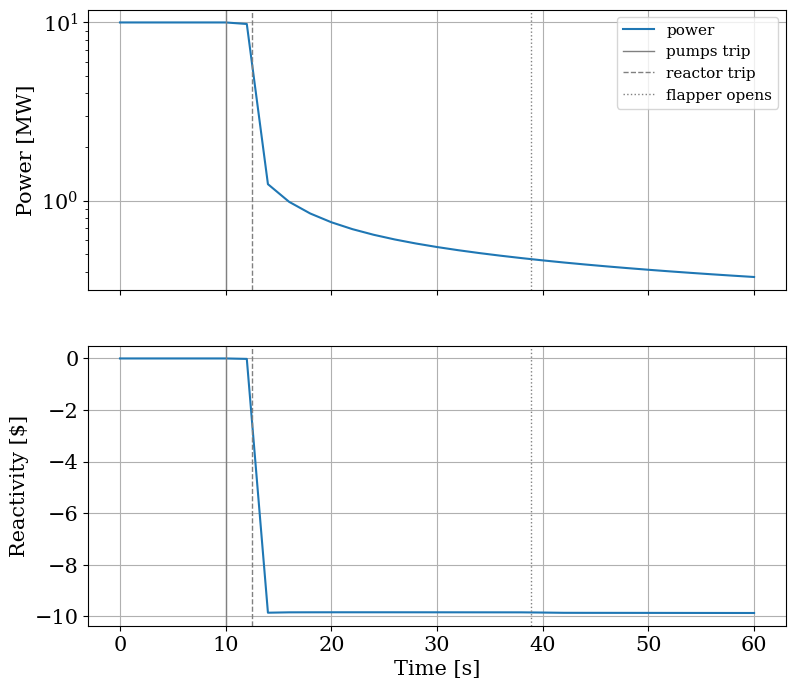

In [6]:
refs["trip"].t_trip = rec.t_trip
early = np.flatnonzero(sol.time <= 60)
reactivity = np.array([agr.save(sol.data[i], t=sol.time[i])["PK"]["reactivity"] for i in early])
power = agr.at_times(sol, refs["pk"], "power")[early]
print(f"reactivity at 60 s: {reactivity[-1] / BETA.sum():.2f} dollars\npower at 60 s:      {power[-1] / p.power * 100:.1f} % of nominal")
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
top.plot(sol.time[early], power / 1e6, label="power")
top.set_yscale("log")
top.set_ylabel("Power [MW]")
bottom.plot(sol.time[early], reactivity / BETA.sum(), label="reactivity")
bottom.set_ylabel("Reactivity [$]")
bottom.set_xlabel("Time [s]")
for ax in (top, bottom):
    mark(ax)
    ax.grid()
top.legend(fontsize=11)
plt.show()

Between the pumps tripping and the reactor trip the power barely moves: the coolant warms as the flow falls, and its negative feedback is small. The rods insert 10 dollars over one second, and the power falls by an order of magnitude within that second, the prompt drop, then decays with the delayed neutrons and settles onto the decay heat. A minute in, the core makes about 3.7 % of its nominal power and the total reactivity is about -9.9 dollars, the rods less a little positive feedback from water and fuel cooler than at the operating point.

## The hot plate

The figure follows the hot plate through the hour: the hottest coolant along its channel and the hottest point of its surface. The horizontal line is the saturation temperature at the pressure of the core top, with 8 m of water above it, the reference for the margin in the record.

saturation temperature:  116.84 °C
peak coolant:            100.87 °C at 280 s
peak surface:            121.58 °C at 198 s
margin to saturation:    15.97 K


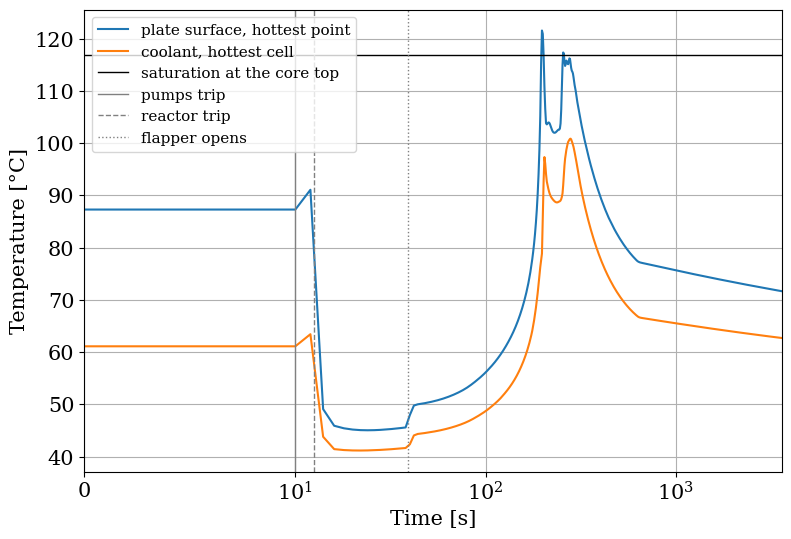

In [7]:
T_sat = float(light_water.sat_temperature(refs["p_ref"]))
T_cool = agr.at_times(sol, refs["channels"]["hot"], "T_cool").max(axis=1)
T_wall = agr.at_times(sol, refs["fuels"]["hot"], "T_wall_left").max(axis=1)
print(f"saturation temperature:  {T_sat:.2f} °C")
print(f"peak coolant:            {T_cool.max():.2f} °C at {sol.time[T_cool.argmax()]:.0f} s")
print(f"peak surface:            {T_wall.max():.2f} °C at {sol.time[T_wall.argmax()]:.0f} s")
print(f"margin to saturation:    {rec.margin:.2f} K")
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(sol.time, T_wall, label="plate surface, hottest point")
ax.plot(sol.time, T_cool, label="coolant, hottest cell")
ax.axhline(T_sat, color="black", linewidth=1, label="saturation at the core top")
mark(ax)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, sol.time[-1])
ax.set_xlabel("Time [s]")
ax.set_ylabel("Temperature [°C]")
ax.legend(fontsize=11)
ax.grid()
plt.show()

The time axis is again linear over the first 10 s and logarithmic after. The hot plate heats while the flow falls at full power, cools as soon as the rods are in, takes a step up when the flapper opens and the core loses part of its flow, and heats again as the flow keeps falling faster than the decay heat. The worst moment is the reversal: at about 198 s, as the hot channel's flow passes through zero and its water barely moves, the plate surface peaks at about 122 °C. The coolant peaks later, at about 101 °C at about 280 s, as the reversed flows settle. It stays about 16 K below the saturation temperature of about 117 °C, which is the margin the record reports. The plate surface, on the other hand, crosses the saturation temperature for a few seconds near each of the two peaks: there the wall can nucleate bubbles locally while the water in the channel stays subcooled. The margin and the run's saturation stop are about the coolant, not the wall. Once the pump legs are still, both temperatures decline with the decay heat.

## Does the energy add up

Over the hour the core feeds energy into the water; the heat exchanger removes it while the pump legs still carry flow, and the rest stays in the water and the plates as a change of their temperatures. `energy_budget` integrates the power and the heat exchanger's duty over the output times and adds up the change of stored energy of every water volume and every plate between the first and last output time.

In [8]:
e = energy_budget(agr, K, refs, sol, p)
parts = e["parts_J"]
water = sum(v for k, v in parts.items() if not k.endswith("_fuel"))
print(f"unaccounted, share of the energy fed: {100 * e['unaccounted_J'] / e['fed_J']:.2f} %")
pd.Series(
    {
        "fed by the core": e["fed_J"],
        "removed by the heat exchanger": e["hx_removed_J"],
        "stored in the water": water,
        "  of which the pool": parts["Pool"],
        "  of which the decay tank": parts["DecayTank"],
        "stored in the plates": e["stored_J"] - water,
        "unaccounted": e["unaccounted_J"],
    }
).div(1e6).round(2).to_frame("energy [MJ]")

unaccounted, share of the energy fed: -0.19 %


,energy [MJ]
fed by the core,716.86
removed by the heat exchanger,532.24
stored in the water,186.24
of which the pool,515.08
of which the decay tank,-329.48
stored in the plates,-0.25
unaccounted,-1.37


The budget closes to about -0.2 % of the energy fed: the energy removed and stored exceeds the energy fed by about 1.4 MJ. The remainder is consistent with the bookkeeping: the power and the heat exchanger's duty are integrated by the trapezoidal rule on the 2 s output grid, which smears the second in which the power drops by an order of magnitude, and the stored energy takes each volume's density and heat capacity at its initial temperature.

The split is worth a look. Of about 717 MJ fed, the heat exchanger removed about 532 MJ even though the pumps tripped at 10 s, and the decay tank lost about 329 MJ. Both are the coastdown at work: the flywheels push the warm water of the decay tank through the heat exchanger and replace it by water at the heat exchanger's outlet temperature. The pool gained about 515 MJ, and that is where the decay heat goes once the legs are still.

## The natural-circulation loop

At the end of the hour the flow runs up the core, down the pool column and back through the flapper into the plenum. `loop_pressure_budget` gives the pressure difference of each component on that loop at the last output time, signed along the loop, so that they sum to the loop law the solver enforces; and the hot plate's buoyancy head, the weight of a column of water at the plenum temperature less that of the hot channel's warmer water.

In [9]:
budget, buoyancy = loop_pressure_budget(agr, K, refs, sol, ["HotChannel", "Flapper", "Pool"])
for name, dp in budget.items():
    print(f"{name:12s} {dp:12.2f} Pa")
print(f"{'sum':12s} {sum(budget.values()):12.1e} Pa")
print(f"hot plate buoyancy head: {buoyancy:.2f} Pa")

HotChannel        6807.09 Pa
Flapper              2.29 Pa
Pool             -6809.37 Pa
sum              -1.2e-10 Pa
hot plate buoyancy head: 39.08 Pa


The sum is zero to the solver's tolerance: that is the loop law holding, and it says nothing more. The physics is in the terms. The hot channel's and the pool's are both close to the weight of a 0.7 m column of water, about 6807 and 6809 Pa with opposite signs; the column in the hot channel is lighter by its buoyancy head, about 39 Pa, and also pays for its friction. What is left between the two columns, about 2.3 Pa, is what the flapper dissipates. Most of the hot plate's buoyancy is spent on driving its own small flow through a 2.2 mm gap; the flapper, carrying the flow of the whole core, needs very little.

The loss of both pumps thus ends in a steady natural circulation through the flapper of about 1.5 kg/s, with the pool as the heat sink: after the hour it is only about 0.41 K warmer. With the pumps gone, buoyancy alone drives that flow, and this page is the library's thermosyphon example. These numbers come from one output grid and one solver tolerance. The next example, *One Pump, a Stuck Flapper, and How Far to Trust the Numbers*, runs the variations of this scenario and asks how much of what this page shows converges with the grid and the tolerance.